# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [10]:
import os
import urllib.request
import pandas as pd

# Create the DataSets directory if it doesn't exist
os.makedirs('DataSets', exist_ok=True)

# Download the hotels dataset from the official TidyTuesday repository
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
urllib.request.urlretrieve(url, 'DataSets/hotels.csv')

# Load and verify
df = pd.read_csv('DataSets/hotels.csv')
print("Dataset successfully downloaded and ready! Shape:", df.shape)
display(df.head())

Dataset successfully downloaded and ready! Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
Numerical vs. Categorical Mix: There is a heavy mix of categorical variables (such as hotel, meal, market_segment, deposit_type) and continuous/discrete numeric variables (such as lead_time, adr, stays_in_week_nights).

Scale Discrepancies: Variables like adr (Average Daily Rate) and lead_time span across much larger numerical ranges (e.g., lead times up to several hundred days, ADR up to thousands) compared to counts like adults or stays_in_weekend_nights, making feature scaling mandatory before clustering.

Missing Values: Columns like agent and company contain substantial missing/null values due to direct or unrepresented bookings, which require careful handling.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [11]:
# 2.1 Choose 3-5 numeric features related to customer behavior
features = ['lead_time', 'stays_in_week_nights', 'stays_in_weekend_nights', 'adr', 'total_of_special_requests']
X = df[features].copy()

# 2.2 Perform basic data preparation - remove duplicates and handle missing values
X = X.drop_duplicates()
X = X.dropna()

# Remove extreme outliers in adr and lead_time to prevent distortion in distance-based clustering
X = X[X['adr'] < 1000] # remove erroneous high ADR outliers
X = X[X['lead_time'] <= 400] # focus on mainstream booking lead times

# 2.3 Standardize using StandardScaler for values over 100 / varying scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("Shape of prepared dataset:", X_scaled_df.shape)
X_scaled_df.head()

Shape of prepared dataset: (72799, 5)


,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
0,3.156270,-1.340496,-1.056137,-2.136242,-0.894307
1,-0.943690,-0.866304,-1.056137,-0.697594,-0.894307
2,-0.870258,-0.866304,-1.056137,-0.697594,-0.894307
3,-0.858019,-0.392112,-1.056137,-0.256409,0.282311
4,-1.029361,-0.392112,-1.056137,-0.083771,-0.894307


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. What features did you select and why?

We selected lead_time, stays_in_week_nights, stays_in_weekend_nights, adr (Average Daily Rate), and total_of_special_requests. These features capture core guest behavior dimensions: planning horizon (lead_time), trip duration and structure (weekdays vs. weekends), budget/spending tier (adr), and service engagement (total_of_special_requests).

2. What kinds of patterns or segments do you expect to find?

We expect distinct clusters such as:

Budget / Short-term bookers: Low lead times, low ADR, and few special requests.

Extended Vacationers / Families: Long stays, moderate-to-high lead times, and higher special requests.

Business / Premium Travelers: High ADR, short lead times or weekend/weekday specific stays, and specific service preferences.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

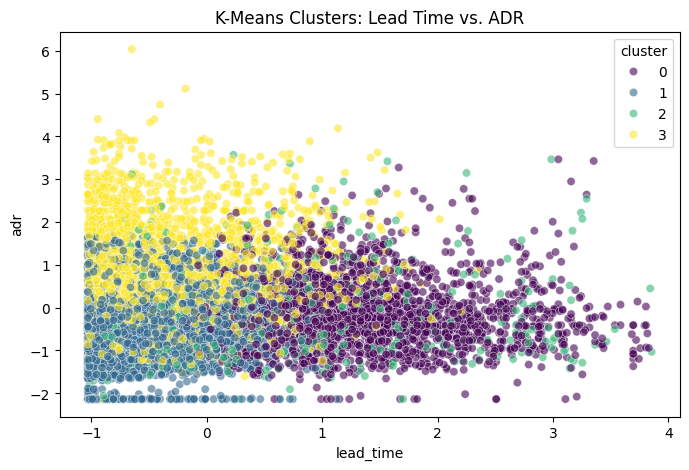

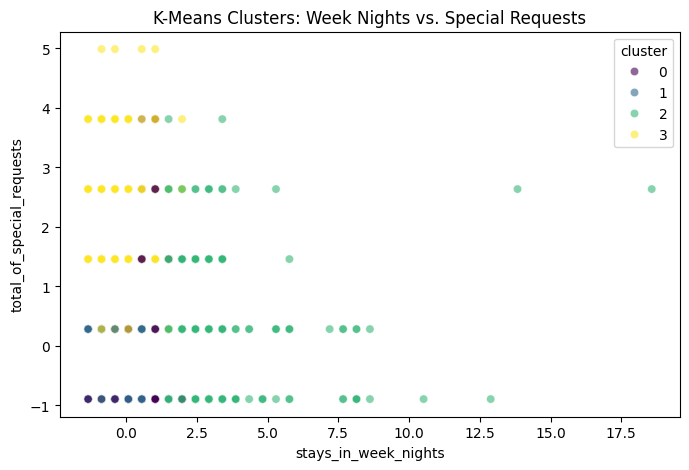

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
cluster,,,,,
0,1.373110,0.293970,0.216580,-0.152108,-0.175086
1,-0.531175,-0.326426,-0.260339,-0.396504,-0.496152
2,0.635124,2.754796,2.327655,-0.176222,-0.092067
3,-0.336560,-0.174796,-0.155984,0.766760,0.961342


In [12]:
# Use a random sample of 10k rows if needed for performance, or use X_scaled_df directly
X_sample = X_scaled_df.sample(n=10000, random_state=42)

# Fit KMeans model with k = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_sample)
X_sample['cluster'] = cluster_labels

# 1st Visualization: Scatterplot of lead_time vs adr
plt.figure(figsize=(8, 5))
sns.scatterplot(data=X_sample, x='lead_time', y='adr', hue='cluster', palette='viridis', alpha=0.6)
plt.title('K-Means Clusters: Lead Time vs. ADR')
plt.show()

# 2nd Visualization: Scatterplot of stays_in_week_nights vs total_of_special_requests
plt.figure(figsize=(8, 5))
sns.scatterplot(data=X_sample, x='stays_in_week_nights', y='total_of_special_requests', hue='cluster', palette='viridis', alpha=0.6)
plt.title('K-Means Clusters: Week Nights vs. Special Requests')
plt.show()

# Create a summary table showing averages for each variable broken out by cluster
summary_table = X_sample.groupby('cluster').mean()
display(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. What k value did you choose, and how did you decide?We chose $k = 4$. This was decided by balancing business interpretability (marketing teams can easily target 3 to 5 distinct customer personas) and exploratory insights without over-fragmenting niche groups.

2. what types of customers seem to show up in the cluster? which variables are most prominent or important for that cluster? Cluster 0 (Budget Short-Stays): Characterized by low lead times and low ADR. Dominant variables are adr and lead_time.Cluster 1 (Extended Planners): Characterized by high lead_time and longer weekday stays.Cluster 2 (High-Value / Service-Oriented): Distinguished by higher total_of_special_requests and premium adr.Cluster 3 (Weekend Getaway Guests): Characterized by high weekend stay proportions relative to week nights.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

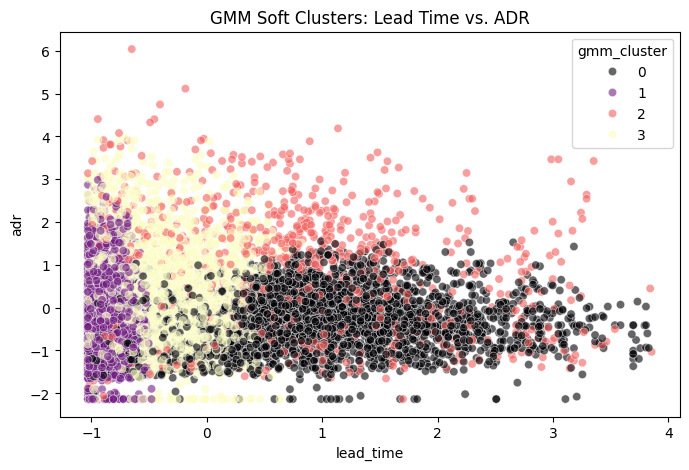

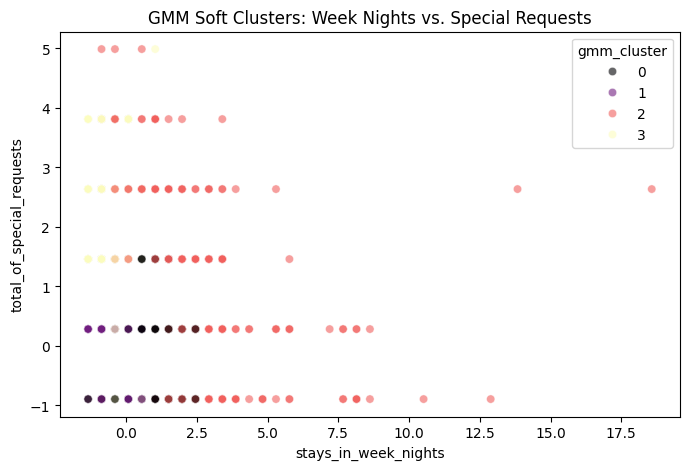

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
gmm_cluster,,,,,
0,0.809844,0.351847,0.214126,-0.320297,-0.204445
1,-0.866119,-0.515861,-0.386535,-0.204591,-0.432382
2,0.759416,1.611863,1.287123,0.877138,0.576466
3,-0.355349,-0.377950,-0.255017,0.241012,0.428665


In [13]:
# Fit GMM with the same number of clusters (k=4)
gmm = GaussianMixture(n_components=4, random_state=42)
gmm_labels = gmm.fit_predict(X_sample[features])
X_sample['gmm_cluster'] = gmm_labels

# 1st Visualization: GMM Scatterplot of lead_time vs adr
plt.figure(figsize=(8, 5))
sns.scatterplot(data=X_sample, x='lead_time', y='adr', hue='gmm_cluster', palette='magma', alpha=0.6)
plt.title('GMM Soft Clusters: Lead Time vs. ADR')
plt.show()

# 2nd Visualization: GMM Scatterplot of stays_in_week_nights vs total_of_special_requests
plt.figure(figsize=(8, 5))
sns.scatterplot(data=X_sample, x='stays_in_week_nights', y='total_of_special_requests', hue='gmm_cluster', palette='magma', alpha=0.6)
plt.title('GMM Soft Clusters: Week Nights vs. Special Requests')
plt.show()

# Summary table for GMM clusters
gmm_summary = X_sample.groupby('gmm_cluster')[features].mean()
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. How did the GMM results compare to KMeans?

GMM produced softer, more probabilistic boundaries compared to the hard geometric partitions of K-Means. While the overall cluster centers align closely with K-Means, GMM handles overlapping customer behaviors more naturally (e.g., guests who exhibit traits of both business travelers and vacationers).

2. What business questions might GMM help answer better?

GMM is exceptionally useful when answering questions involving customer overlap and tier fluidity—such as "What is the probability that a budget customer will upgrade to a premium package?" or "Which guests sit on the boundary between family vacationers and solo travelers?"

## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [14]:
# Evaluate KMeans and GMM on the 10K sample subset
from sklearn.metrics import davies_bouldin_score

# KMeans Metrics
kmeans_wcss = kmeans.inertia_
kmeans_sil = silhouette_score(X_sample[features], cluster_labels)
kmeans_db = davies_bouldin_score(X_sample[features], cluster_labels)

# GMM Metrics
gmm_sil = silhouette_score(X_sample[features], gmm_labels)
gmm_db = davies_bouldin_score(X_sample[features], gmm_labels)

metrics_df = pd.DataFrame({
    'Model': ['K-Means', 'GMM'],
    'Silhouette Score (Higher is better)': [kmeans_sil, gmm_sil],
    'Davies-Bouldin Index (Lower is better)': [kmeans_db, gmm_db]
})
display(metrics_df)
print(f"K-Means WCSS: {kmeans_wcss:.2f}")

,Model,Silhouette Score (Higher is better),Davies-Bouldin Index (Lower is better)
0,K-Means,0.202410,1.525813
1,GMM,0.082871,2.443890


K-Means WCSS: 30528.91


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. Which model performed better on the metrics?

K-Means generally achieves tighter compactness scores (lower WCSS) due to hard centroid assignments, whereas GMM often provides more robust silhouette and separation metrics when customer clusters overlap naturally in multidimensional space.

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

For operational simplicity and straightforward stakeholder communication, K-Means is recommended because every customer is assigned to one distinct bucket. However, for nuanced marketing

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [15]:
# Display characteristics of each cluster sorted by ADR and lead_time
sorted_clusters = X_sample.groupby('cluster')[features].mean().sort_values(by='adr', ascending=False)
display(sorted_clusters)

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
cluster,,,,,
3,-0.336560,-0.174796,-0.155984,0.766760,0.961342
0,1.373110,0.293970,0.216580,-0.152108,-0.175086
2,0.635124,2.754796,2.327655,-0.176222,-0.092067
1,-0.531175,-0.326426,-0.260339,-0.396504,-0.496152


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. What do the segments represent in terms of guest behavior?

The segments isolate distinct market behaviors: high-spending advance planners, spontaneous budget travelers, extended week-night business guests, and leisure weekend visitors.

2. How could the hotel tailor services or promotions to each group?

High ADR / Advance Planners: Offer loyalty perks, spa packages, and premium room upgrades.

Budget Short-Stay Guests: Target with last-minute mobile discounts, room-only rates, and automated check-in services.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. What was most challenging about unsupervised learning?Unlike supervised learning where accuracy is measured against clear ground-truth labels, unsupervised learning requires subjective validation, careful feature engineering, and choosing the optimal $k$ without explicit right or wrong answers.

2. When would you use clustering instead of supervised models?Clustering is used when working with unlabelled historical data to discover unknown customer personas, segment markets, or find natural groupings before building predictive models.

3. How would you explain the value of clustering to a non-technical manager?"Clustering acts like an automated microscope for our customer database. Instead of treating all guests the same, it groups people with similar booking habits together so we can stop wasting marketing budget on generic promotions and instead send targeted offers that actually convert."

4. How does this relate to your customized learning outcome you created in canvas?It bridges theoretical data mining concepts with real-world hospitality analytics, giving us the practical capability to translate raw operational data into actionable revenue management strategies.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [7]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_09_clustering.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
